# Nguyễn Thành Trí - MSSV: 6451071079
## Bài 4: Phân loại nấm độc hay ăn được Mushroom Classification (Mục 6 trang 27)

In [1]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.naive_bayes import GaussianNB
from sklearn import metrics

def get_data_path(rel_path):
    candidates = [
        rel_path,
        os.path.join("..", rel_path),
        os.path.join("..", "..", rel_path),
        os.path.join("Dataset", os.path.basename(rel_path)),
        os.path.join("..", "Dataset", os.path.basename(rel_path)),
        os.path.join("..", "..", "Dataset", os.path.basename(rel_path))
    ]
    for p in candidates:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"Không tìm thấy file: {rel_path}")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


### Câu 4: Nhập dữ liệu và tách các cột thành hai phần (features và labels)
- Đọc tập dữ liệu mushrooms.csv.
- Phần 1 (X): Chứa 22 thuộc tính hình thái cây nấm (features).
- Phần 2 (y): Chứa thuộc tính quyết định 'class' ('p': độc, 'e': ăn được).

In [2]:
# Câu 4: Tách các cột dữ liệu thành hai phần
mush_path = get_data_path("mushrooms.csv")
df_mush = pd.read_csv(mush_path)

X = df_mush.drop(columns=['class'])
y = df_mush['class']

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")
print(f"Kích thước tập dữ liệu gốc: {df_mush.shape}")
print(f"Kích thước tập thuộc tính dự đoán (X): {X.shape}")
print(f"Kích thước thuộc tính quyết định (y): {y.shape}")
print(f"Phân bố lớp mục tiêu: Ăn được (e) = {(y == 'e').sum()}, Nấm độc (p) = {(y == 'p').sum()}")
display(df_mush.head())

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Kích thước tập dữ liệu gốc: (8124, 23)
Kích thước tập thuộc tính dự đoán (X): (8124, 22)
Kích thước thuộc tính quyết định (y): (8124,)
Phân bố lớp mục tiêu: Ăn được (e) = 4208, Nấm độc (p) = 3916


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


### Câu 5: Chuyển đổi các cột không phải dạng số về dạng one-hot vector
- Toàn bộ 22 thuộc tính hình thái cây nấm đều là dữ liệu định danh (categorical).
- Áp dụng pd.get_dummies() để chuyển đổi toàn bộ đặc trưng sang vector one-hot.

In [3]:
# Câu 5: Chuyển đổi các cột không phải dạng số về dạng one-hot vector
categorical_cols = X.select_dtypes(include=['object', 'string']).columns
print(f"Số lượng thuộc tính định danh cần mã hóa: {len(categorical_cols)}")

X_encoded = pd.get_dummies(X, columns=categorical_cols, dtype=int)

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")
print(f"Kích thước tập dữ liệu sau khi mã hóa One-Hot: {X_encoded.shape}")
display(X_encoded.head())

Số lượng thuộc tính định danh cần mã hóa: 22
Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Kích thước tập dữ liệu sau khi mã hóa One-Hot: (8124, 117)


,cap-shape_b,cap-shape_c,cap-shape_f,cap-shape_k,cap-shape_s,cap-shape_x,cap-surface_f,cap-surface_g,cap-surface_s,cap-surface_y,...,population_s,population_v,population_y,habitat_d,habitat_g,habitat_l,habitat_m,habitat_p,habitat_u,habitat_w
0,0,0,0,0,0,1,0,0,1,0,...,1,0,0,0,0,0,0,0,1,0
1,0,0,0,0,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
2,1,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,1,0,0,0
3,0,0,0,0,0,1,0,0,0,1,...,1,0,0,0,0,0,0,0,1,0
4,0,0,0,0,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0


### Câu 6: Tách các dòng dữ liệu ra thành hai phần huấn luyện và kiểm thử
- Sử dụng hàm train_test_split chia 70% huấn luyện và 30% kiểm thử theo đề bài:
  `train_test_split(X, y, test_size=0.3, random_state=42)`

In [4]:
# Câu 6: Tách các dòng dữ liệu ra thành hai phần huấn luyện 70% và kiểm thử 30%
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.3, random_state=42)

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")
print(f"Kích thước tập huấn luyện X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"Kích thước tập kiểm thử X_test: {X_test.shape}, y_test: {y_test.shape}")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Kích thước tập huấn luyện X_train: (5686, 117), y_train: (5686,)
Kích thước tập kiểm thử X_test: (2438, 117), y_test: (2438,)


### Câu 7: Xây dựng cây ID3 dựa trên dữ liệu huấn luyện và kiểm thử
- Sử dụng DecisionTreeClassifier với tiêu chí entropy.
- Đánh giá độ chính xác, báo cáo phân lớp và ma trận nhầm lẫn.
- Biểu diễn cấu trúc cây quyết định ID3.

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
ID3 Decision Tree Accuracy: 1.0000

Báo cáo phân lớp (Classification Report):
              precision    recall  f1-score   support

           e       1.00      1.00      1.00      1257
           p       1.00      1.00      1.00      1181

    accuracy                           1.00      2438
   macro avg       1.00      1.00      1.00      2438
weighted avg       1.00      1.00      1.00      2438



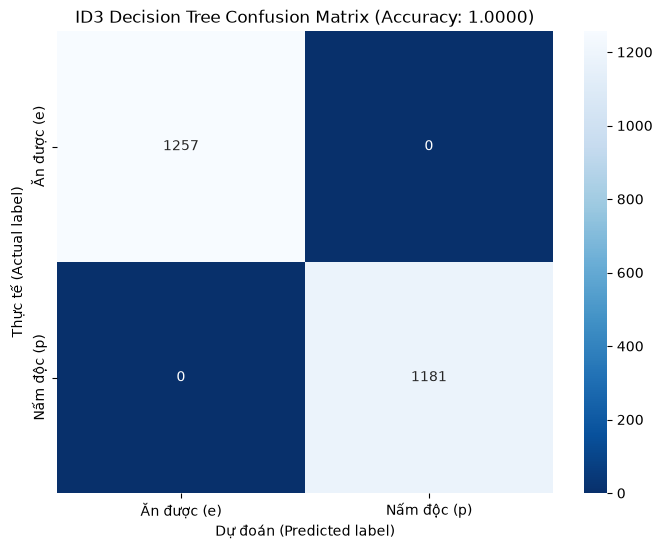

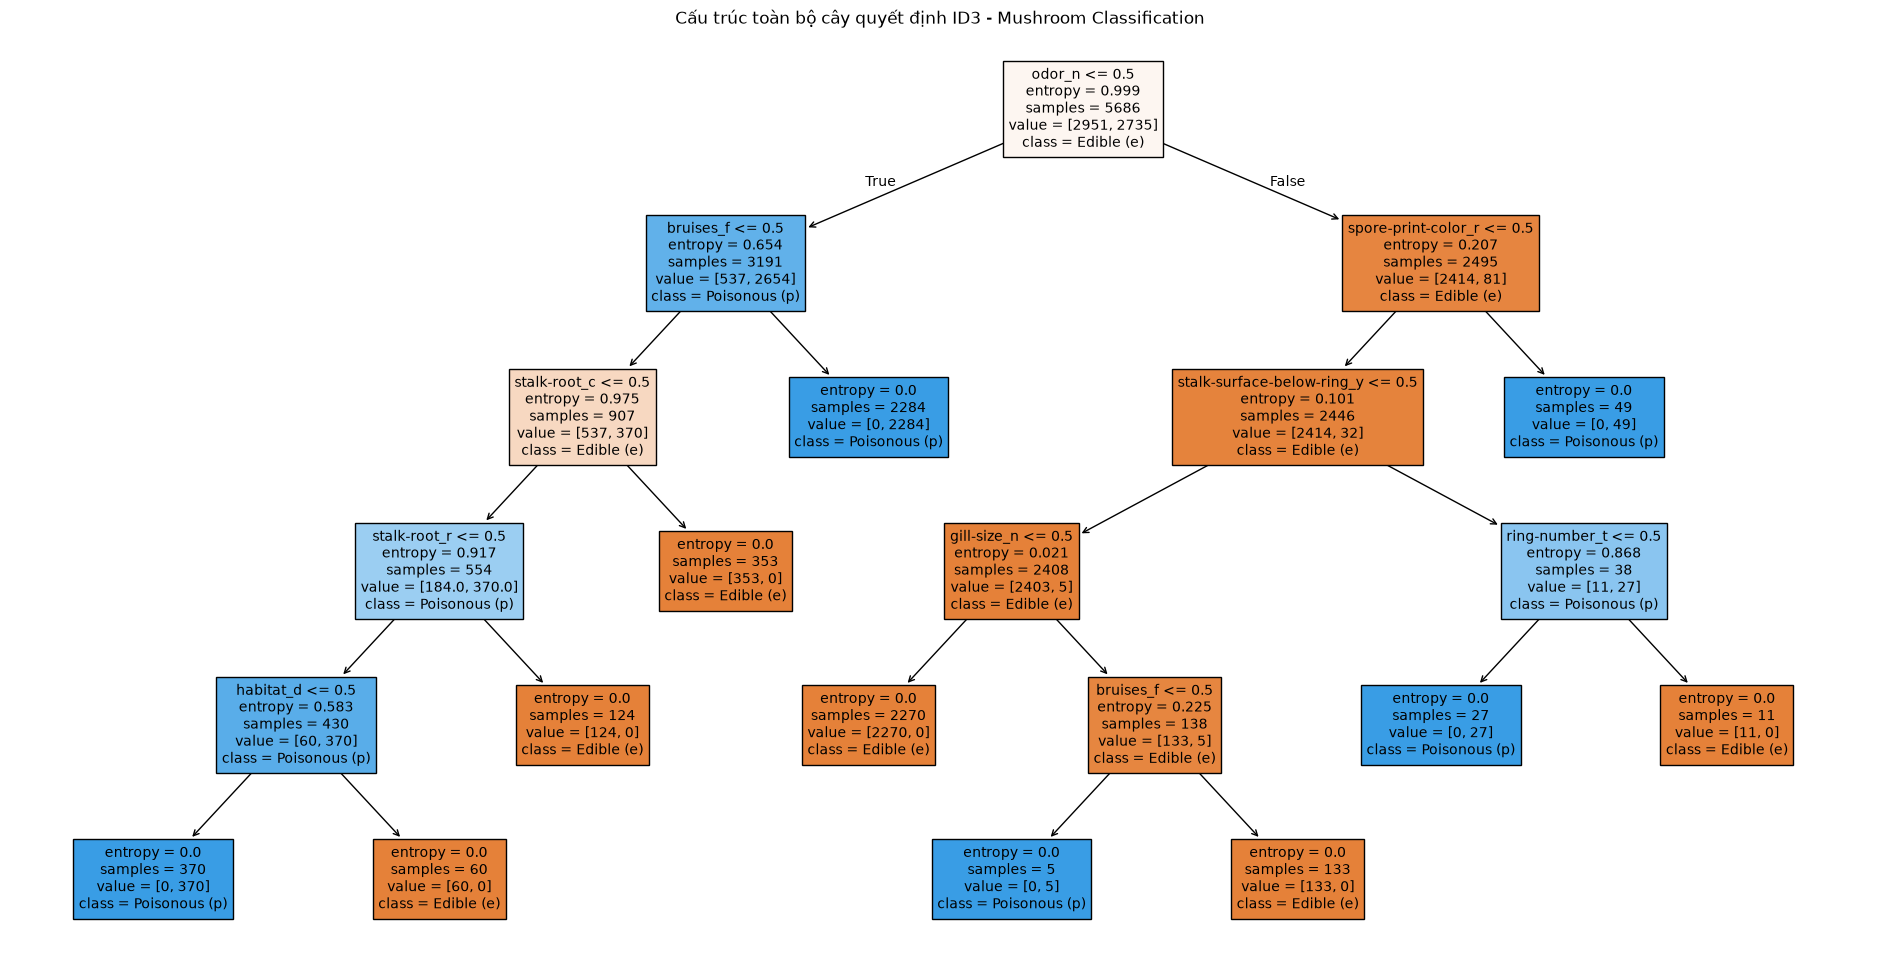

In [5]:
# Câu 7: Xây dựng cây ID3
clf_id3 = tree.DecisionTreeClassifier(criterion="entropy", random_state=42)
clf_id3.fit(X_train, y_train)

# Dự đoán trên tập kiểm thử
id3_pred = clf_id3.predict(X_test)
id3_score = metrics.accuracy_score(y_test, id3_pred)

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")
print(f"ID3 Decision Tree Accuracy: {id3_score:.4f}")
print()
print("Báo cáo phân lớp (Classification Report):")
print(metrics.classification_report(y_test, id3_pred))

# Ma trận nhầm lẫn
id3_cm = metrics.confusion_matrix(y_test, id3_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(id3_cm, annot=True, fmt="d", cmap="Blues_r",
            xticklabels=['Ăn được (e)', 'Nấm độc (p)'],
            yticklabels=['Ăn được (e)', 'Nấm độc (p)'])
plt.xlabel("Dự đoán (Predicted label)")
plt.ylabel("Thực tế (Actual label)")
plt.title(f"ID3 Decision Tree Confusion Matrix (Accuracy: {id3_score:.4f})")
plt.show()

# Biểu diễn cây quyết định ID3
plt.figure(figsize=(24, 12))
tree.plot_tree(clf_id3, feature_names=X_encoded.columns.tolist(),
               class_names=['Edible (e)', 'Poisonous (p)'], filled=True, fontsize=10)
plt.title("Cấu trúc toàn bộ cây quyết định ID3 - Mushroom Classification")
plt.show()

### Câu 8: Xây dựng cây CART dựa trên dữ liệu huấn luyện và kiểm thử
- Sử dụng mô hình DecisionTreeClassifier với tiêu chí gini (Gini Impurity).
- Đánh giá độ chính xác, báo cáo phân lớp và ma trận nhầm lẫn.
- Biểu diễn cấu trúc cây quyết định CART.

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
CART Decision Tree Accuracy: 1.0000

Báo cáo phân lớp (Classification Report):
              precision    recall  f1-score   support

           e       1.00      1.00      1.00      1257
           p       1.00      1.00      1.00      1181

    accuracy                           1.00      2438
   macro avg       1.00      1.00      1.00      2438
weighted avg       1.00      1.00      1.00      2438



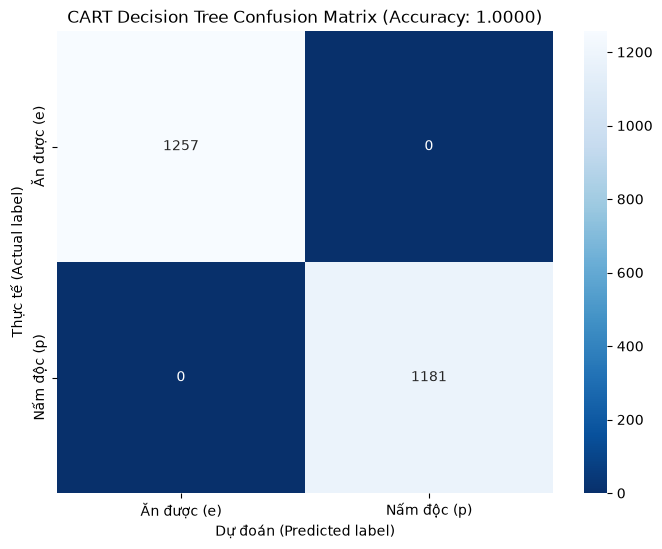

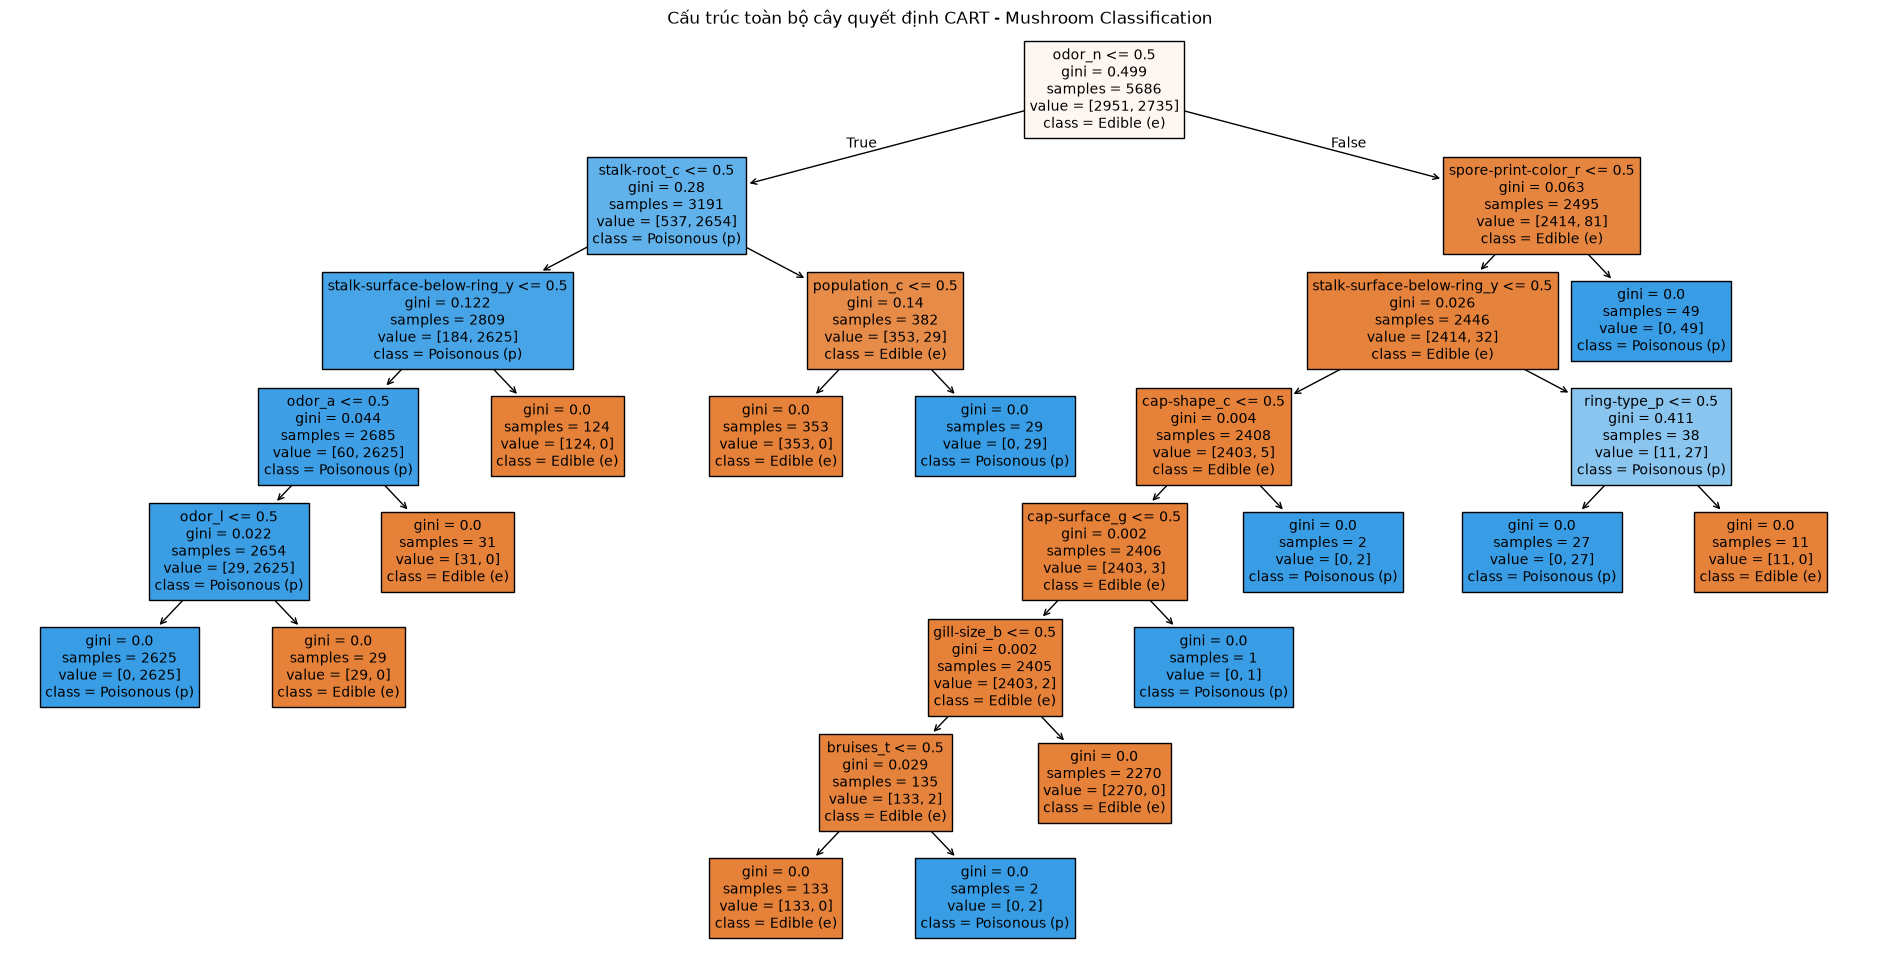

In [6]:
# Câu 8: Xây dựng cây CART
clf_cart = tree.DecisionTreeClassifier(criterion="gini", random_state=42)
clf_cart.fit(X_train, y_train)

# Dự đoán trên tập kiểm thử
cart_pred = clf_cart.predict(X_test)
cart_score = metrics.accuracy_score(y_test, cart_pred)

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")
print(f"CART Decision Tree Accuracy: {cart_score:.4f}")
print()
print("Báo cáo phân lớp (Classification Report):")
print(metrics.classification_report(y_test, cart_pred))

# Ma trận nhầm lẫn
cart_cm = metrics.confusion_matrix(y_test, cart_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cart_cm, annot=True, fmt="d", cmap="Blues_r",
            xticklabels=['Ăn được (e)', 'Nấm độc (p)'],
            yticklabels=['Ăn được (e)', 'Nấm độc (p)'])
plt.xlabel("Dự đoán (Predicted label)")
plt.ylabel("Thực tế (Actual label)")
plt.title(f"CART Decision Tree Confusion Matrix (Accuracy: {cart_score:.4f})")
plt.show()

# Biểu diễn cây quyết định CART
plt.figure(figsize=(24, 12))
tree.plot_tree(clf_cart, feature_names=X_encoded.columns.tolist(),
               class_names=['Edible (e)', 'Poisonous (p)'], filled=True, fontsize=10)
plt.title("Cấu trúc toàn bộ cây quyết định CART - Mushroom Classification")
plt.show()